# 2.1 $\quad$ Portfolio Generation

## 1. Return and volatility of a two-asset portfolio

A **portfolio** is a collection of financial assets, such as stocks, bonds, and other investment instruments. The portfolio composition is chosen with the **objective** of achieving a specific financial goal, such as maximizing return, minimizing risk, or finding a suitable balance between the two. **Portfolio management** involves making strategic decisions about asset allocation, diversification, and periodic adjustments to adapt to possible changes in market conditions.

Defining an asset portfolio requires specifying the financial instruments or assets included in it and the proportion invested in each one. Let:

* $w_1$ be the proportion invested in asset $1$ $\Rightarrow w_2=1-w_1$. We must have $w_1 + w_2 = 1.0$, since the weights represent 100% of the investment.

* $\bar R_p$ be the mean or expected return of the portfolio $\Rightarrow \bar R_p=w_1 \bar R_1 + w_2 \bar R_2$. It is a weighted average of the return of each asset, using the investment weight $w_i$ of each asset.

* Variance $\sigma_{P}^2 = w_1^2 \sigma_{1}^2 + w_2^2 \sigma_{2}^2 + 2 w_1 w_2 \sigma_{12}$, where $\sigma_{12}$ is the covariance between assets 1 and 2. Therefore, portfolio variance is affected by the covariance ($\sigma_{12}$) between the assets.

* Volatility $\sigma_{P} = \sqrt{\sigma_{P}^2}$

Rearranging the expression and writing covariance as a function of correlation:

$\sigma_{P}^2 = w_1^2 \sigma_{1}^2 + w_2^2 \sigma_{2}^2 + 2 w_1 w_2 \sigma_{12}$ where $\sigma_{12} = Cov(r_1,r_2)$

If:

$Corr(r_1,r_2) = \frac{Cov(r_1,r_2)}{\sigma_{r_1}\sigma_{r_2}} \implies Cov(r_1,r_2) = \sigma_{r_1}\sigma_{r_2} Corr(r_1,r_2) = \sigma_1\sigma_2\rho_{12}$

Therefore:

$\sigma_{P}^2 = w_1^2 \sigma_{1}^2 + w_2^2 \sigma_{2}^2 + 2 w_1 w_2 \sigma_1\sigma_2 \rho_{12} \implies \sigma_{P} = \sqrt{w_1^2 \sigma_{1}^2 + w_2^2 \sigma_{2}^2 + 2 w_1 w_2 \sigma_1\sigma_2 \rho_{12}}$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

We define two functions:

* **calc_portfolio_return**: given a portfolio, it returns the expected return.

* **calc_portfolio_std**: given a portfolio, it returns the portfolio volatility.

* We also define an example portfolio with two assets.

In [2]:
def calc_portfolio_return(w1: float, w2: float, r1: float, r2: float) -> float:
    """Calculate the expected return of a two-asset portfolio.

    Args:
        w1 (float): Weight of asset 1 in the portfolio.
        w2 (float): Weight of asset 2 in the portfolio.
        r1 (float): Expected return of asset 1.
        r2 (float): Expected return of asset 2.

    Returns:
        float: Expected portfolio return.
    """

    return w1 * r1 + w2 * r2


### Same function with parameter validation

The following version performs the same calculation, but first checks that:

- all inputs are numeric;
- the portfolio weights add up to 1.

If any condition is not satisfied, the function raises an error instead of returning an incorrect result.

In [3]:
def calc_portfolio_return(w1: float, w2: float, r1: float, r2: float) -> float:
    """Calculate the expected return of a two-asset portfolio.

    Args:
        w1 (float): Weight of asset 1 in the portfolio.
        w2 (float): Weight of asset 2 in the portfolio.
        r1 (float): Expected return of asset 1.
        r2 (float): Expected return of asset 2.

    Returns:
        float: Expected portfolio return.
    """

    # Check that all arguments are numeric
    for name, value in {"w1": w1, "w2": w2, "r1": r1, "r2": r2}.items():
        if not isinstance(value, (int, float)):
            raise TypeError(f"{name} must be a numeric value")

    # Check that the portfolio weights add up to 1
    if not abs((w1 + w2) - 1) < 1e-8:
        raise ValueError("Portfolio weights must add up to 1")

    return w1 * r1 + w2 * r2

In [4]:
def calc_portfolio_std(
    w1: float, w2: float, std1: float, std2: float, rho: float
) -> float:
    """Calculate the standard deviation of a two-asset portfolio.

    Args:
        w1 (float): Weight of asset 1 in the portfolio.
        w2 (float): Weight of asset 2 in the portfolio.
        std1 (float): Standard deviation of asset 1.
        std2 (float): Standard deviation of asset 2.
        rho (float): Correlation coefficient between the assets.

    Returns:
        float: Portfolio standard deviation.
    """

    return np.sqrt(w1**2 * std1**2 + w2**2 * std2**2 + 2 * w1 * w2 * std1 * std2 * rho)


In [5]:
# Define a two-asset portfolio
ret1 = 0.2  # expected return of asset 1
ret2 = 0.1  # expected return of asset 2

std1 = 0.25  # volatility of asset 1
std2 = 0.15  # volatility of asset 2

p1 = 0.4  # weight of asset 1
p2 = 0.6  # weight of asset 2


---

### Case 1:  
$\quad \rho_{12} = 1$

* If $\rho_{12} = 1$, the assets are said to be **perfectly positively correlated**.

    - There are no diversification benefits.

    - Portfolio return is equal to the weighted sum of the asset returns.
        - $E(\tilde R_P) = w_1 E(\tilde R_1) + w_2 E(\tilde R_2)$
        $$$$

    - Portfolio volatility is equal to the weighted sum of the asset volatilities.

        If $\rho_{12} = 1$

        $\sigma_{P} = \sqrt{w_1^2 \sigma_{1}^2 + w_2^2 \sigma_{2}^2 + 2 w_1 w_2 \sigma_1\sigma_2 \rho_{12}} = \sqrt{w_1^2 \sigma_{1}^2 + w_2^2 \sigma_{2}^2 + 2 w_1 w_2 \sigma_1\sigma_2} = \sqrt{(w_1\sigma_{1})^2 + (w_2\sigma_{2})^2 + 2(w_1\sigma_1)(w_2\sigma_2)}$

        If $(x+y)^2 = 2x+2y+2xy$

        $\sigma_P = w_1 \sigma_1 + w_2 \sigma_2$

In [6]:
# Define the correlation coefficient
corr_coef = 1


In [7]:
print(f"Portfolio return: {100*calc_portfolio_return(p1, p2, ret1, ret2):.2f} %")
print(
    f"Portfolio volatility: {100*calc_portfolio_std(p1, p2, std1, std2, corr_coef):.2f} %"
)


Portfolio return: 14.00 %
Portfolio volatility: 19.00 %


We will vary the weights of the two assets and observe how portfolio return and volatility change.

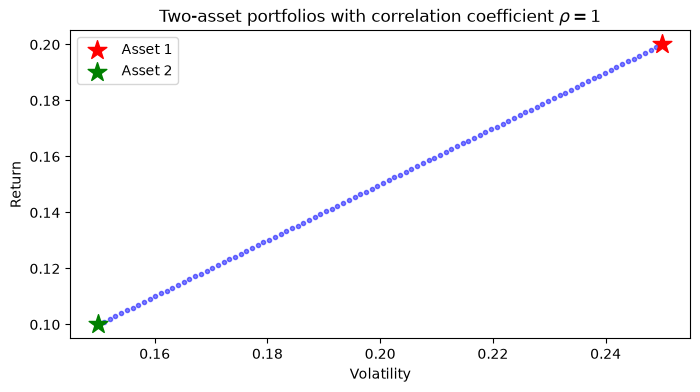

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))

weights_1 = np.linspace(
    0, 1, 100
)  # Generate 100 points between 0 and 1 representing the weight of asset 1

for w_1 in weights_1:
    w_2 = 1 - w_1  # Calculate the weight of asset 2

    ret_p = calc_portfolio_return(
        w_1, w_2, ret1, ret2
    )  # Calculate portfolio return for each weight
    std_p = calc_portfolio_std(
        w_1, w_2, std1, std2, corr_coef
    )  # Calculate portfolio volatility for each weight

    plt.scatter(
        x=std_p, y=ret_p, marker=".", color="blue", alpha=0.5
    )  # Plot the portfolio

plt.scatter(
    x=std1, y=ret1, color="red", marker="*", s=200, label="Asset 1"
)
plt.scatter(
    x=std2, y=ret2, color="green", marker="*", s=200, label="Asset 2"
)

plt.xlabel("Volatility")
plt.ylabel("Return")
plt.title(r"Two-asset portfolios with correlation coefficient $\rho=1$")
plt.legend()
plt.show()


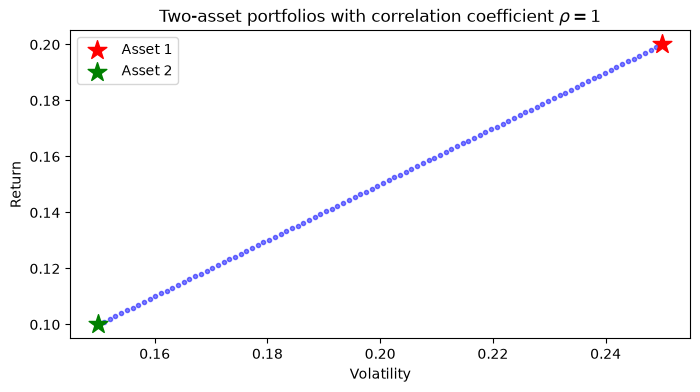

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))

# Generate 100 weights for asset 1
weights_1 = np.linspace(0, 1, 100)

# Lists to store portfolio return and volatility
returns = []
volatilities = []

for w_1 in weights_1:
    w_2 = 1 - w_1

    # Calculate portfolio return and volatility
    ret_p = calc_portfolio_return(w_1, w_2, ret1, ret2)
    std_p = calc_portfolio_std(w_1, w_2, std1, std2, corr_coef)

    # Store the results
    returns.append(ret_p)
    volatilities.append(std_p)

# Plot all portfolios at once
plt.scatter(
    volatilities,
    returns,
    marker=".",
    color="blue",
    alpha=0.5
)

# Plot the individual assets
plt.scatter(std1, ret1, color="red", marker="*", s=200, label="Asset 1")
plt.scatter(std2, ret2, color="green", marker="*", s=200, label="Asset 2")

plt.xlabel("Volatility")
plt.ylabel("Return")
plt.title(r"Two-asset portfolios with correlation coefficient $\rho=1$")
plt.legend()
plt.show()

---

We will now build portfolios using the returns of two downloaded assets.

In [10]:
# Download from GitHub

file_path = "https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python/refs/heads/Feb-2025/Tema_1_Activos_Intro/data/precios_corr_pos.csv"
prices_pos_df = pd.read_csv(file_path, index_col=0, parse_dates=True)
prices_pos_df.columns = ["Asset 1", "Asset 2"]
prices_pos_df.head()


,Asset 1,Asset 2
2010-01-04,117.000000,158.000000
2010-01-05,113.192375,156.263037
2010-01-06,111.121152,155.307702
2010-01-07,107.084666,153.467719
2010-01-08,105.076790,152.540900


In [11]:
# # Load asset prices from a local file
# prices_pos_df = pd.read_csv(
#     "../data/precios_corr_pos.csv", index_col=0, parse_dates=True
# )
# prices_pos_df.columns = ["Asset 1", "Asset 2"]
# prices_pos_df.head()


In [12]:
# Calculate logarithmic returns
returns_pos_df = np.log(prices_pos_df).diff().dropna()


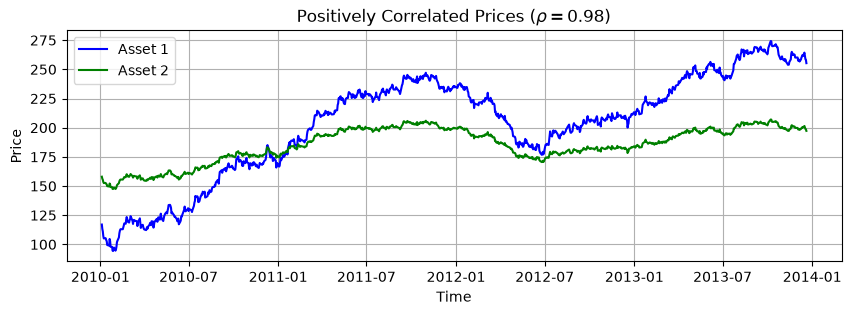

In [13]:
# Plot prices and show the return correlation coefficient in the title
plt.figure(figsize=(10, 3))

corr_pos = returns_pos_df.corr().iloc[0, 1]

plt.plot(prices_pos_df["Asset 1"], label="Asset 1", color="blue")
plt.plot(prices_pos_df["Asset 2"], label="Asset 2", color="green")

plt.title(f"Positively Correlated Prices ($\\rho={corr_pos:.2f}$)")
plt.xlabel("Time")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.show()


As shown in the figure, a **positive correlation** means that when one asset rises, the other tends to rise as well, and vice versa. In other words, the two assets are highly positively correlated.

When we have daily, weekly, or other periodic prices or returns, portfolio parameters such as return and volatility can be calculated in two different ways:

* Using the equations above.
* Treating the portfolio as a single asset.

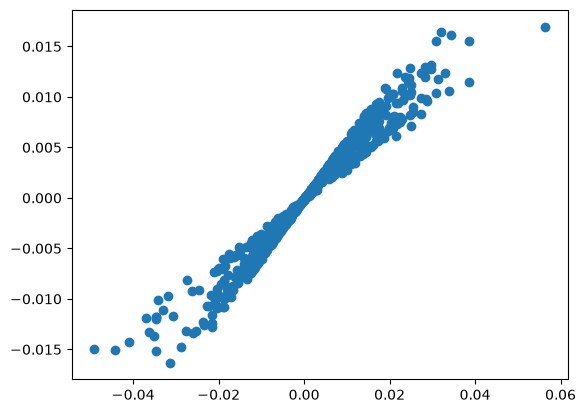

In [14]:
plt.scatter(returns_pos_df['Asset 1'], returns_pos_df['Asset 2'])

#### Using the equations above

We need to calculate the mean and volatility of returns and the correlation between the two assets.

In [15]:
# Calculate the mean and standard deviation of returns
mean_pos = returns_pos_df.mean()
std_pos = returns_pos_df.std()

mean_pos, std_pos


(Asset 1    0.000781
 Asset 2    0.000222
 dtype: float64,
 Asset 1    0.011965
 Asset 2    0.005326
 dtype: float64)

In [16]:
# Calculate the correlation matrix of the two assets
correlation_matrix = returns_pos_df.corr()
rho = correlation_matrix.values[0, 1]

rho


np.float64(0.9801402288728873)

In [17]:
# Define portfolio weights
w1 = 0.8
w2 = 0.2


In [18]:
# Calculate portfolio return
r1 = mean_pos.iloc[0]
r2 = mean_pos.iloc[1]

print("Portfolio return:", calc_portfolio_return(w1, w2, r1, r2))


Portfolio return: 0.0006692986940257982


In [19]:
# Calculate portfolio volatility
vol1 = std_pos.iloc[0]
vol2 = std_pos.iloc[1]

print("Portfolio volatility:", calc_portfolio_std(w1, w2, vol1, vol2, rho))


Portfolio volatility: 0.010618201150274205


#### Treating the portfolio as a single asset

Using the daily returns of each asset and the portfolio weights, we can calculate the daily portfolio returns. From that point on, we can treat the portfolio as a single asset and calculate its return and volatility.

In [20]:
# Calculate daily portfolio returns
weights = np.array([w1, w2])  # (1, 2)

portfolio_returns = returns_pos_df @ weights.T  # (999, 2) @ (2, 1) = (999, 1)

portfolio_returns


2010-01-05   -0.028679
2010-01-06   -0.016001
2010-01-07   -0.031985
2010-01-08   -0.016354
2010-01-11    0.002600
                ...   
2013-12-16    0.010026
2013-12-17   -0.010063
2013-12-18   -0.009953
2013-12-19   -0.001246
2013-12-20   -0.010755
Length: 999, dtype: float64

In [21]:
print("Portfolio return:", portfolio_returns.mean())

# Portfolio return: 0.0006692986940257982


Portfolio return: 0.0006692986940257982


In [22]:
print("Portfolio volatility:", portfolio_returns.std())

# Portfolio volatility: 0.010618201150274205


Portfolio volatility: 0.010618201150274204


---

We will generate 1,000 random portfolios and plot them.

In [23]:
# Random number generator
rng = np.random.default_rng(42)  # Set seed for reproducibility

# Generate random weights
num_portfolios = 1000

weights = rng.random(
    size=(num_portfolios, 2)
)  # Uniform distribution between 0 and 1 -> [0.0, 1.0)
weights = weights / np.sum(
    weights, axis=1, keepdims=True
)  # Normalize so that each row sums to 1

weights.shape


(1000, 2)

In [24]:
def asset_performance(returns: pd.Series) -> tuple:
    """Calculate the return and risk of an individual asset.

    Args:
        returns (pd.Series): Time series of asset returns.

    Returns:
        tuple: Expected return and standard deviation of returns.
    """

    r_a = returns.mean()
    std_a = returns.std()

    return r_a, std_a


In [25]:
def portfolio_performance(weights: np.ndarray, returns: pd.DataFrame) -> tuple:
    """Calculate portfolio return and risk from asset weights and returns.

    Args:
        weights (np.ndarray): Weight of each asset in the portfolio.
        returns (pd.DataFrame): Time series of asset returns.

    Returns:
        tuple: Expected return and standard deviation of portfolio returns.
    """

    portfolio_returns = returns @ weights.T

    r_p = portfolio_returns.mean(axis=0)
    std_p = portfolio_returns.std(axis=0)

    return r_p, std_p


In [26]:
# Function to plot portfolios on a single axis
def plot_on_axis(
    ret_mean: float,
    ret_std: float,
    asset1_mean: float,
    asset1_std: float,
    asset2_mean: float,
    asset2_std: float,
    color: str,
    marker: str,
    title: str,
    corr: float,
):
    # Initialize figure
    plt.figure(figsize=(14, 4))

    plt.scatter(ret_std, ret_mean, c=color, marker=marker, alpha=0.4, label=None)
    plt.scatter(asset1_std, asset1_mean, c="red", marker="*", s=150, label="Asset 1")
    plt.scatter(asset2_std, asset2_mean, c="green", marker="*", s=150, label="Asset 2")

    plt.title(f"{title} ($\\rho={corr:.2f}$)")
    plt.xlabel("Risk (Standard Deviation)")
    plt.ylabel("Return (Mean Return)")
    plt.legend(loc="upper left")
    plt.grid(True)

    plt.tight_layout()
    plt.show()


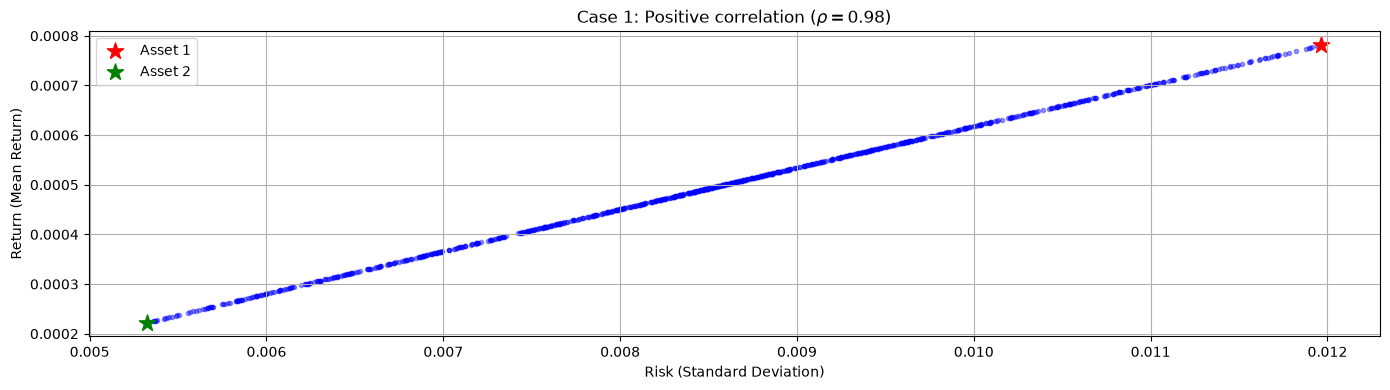

In [27]:
# Expected return and risk of asset 1
asset1_pos_mean, asset1_pos_std = asset_performance(returns_pos_df["Asset 1"])
# Expected return and risk of asset 2
asset2_pos_mean, asset2_pos_std = asset_performance(returns_pos_df["Asset 2"])
# Expected returns and risks of all calculated portfolios
ret_pos_mean, ret_pos_std = portfolio_performance(
    weights, returns_pos_df
)  # weights.shape = (1000, 2)

# Plot
plot_on_axis(
    ret_pos_mean,
    ret_pos_std,
    asset1_pos_mean,
    asset1_pos_std,
    asset2_pos_mean,
    asset2_pos_std,
    "blue",
    ".",
    "Case 1: Positive correlation",
    corr_pos,
)


---

### Case 2:  
$\quad \rho_{12} = -1$

* If $\rho_{12} = -1$, the assets are said to be **perfectly negatively correlated**.

    - Diversification benefits are maximized.

    - Portfolio return is unchanged (remember that it **does not depend on the relationship between the assets**).
        - $E(\tilde R_P) = w_1 E(\tilde R_1) + w_2 E(\tilde R_2)$
        $$$$

    - Portfolio volatility is equal to the weighted difference in the asset volatilities.

        If $\rho_{12} = -1$

        $\sigma_{P} = \sqrt{w_1^2 \sigma_{1}^2 + w_2^2 \sigma_{2}^2 + 2 w_1 w_2 \sigma_1\sigma_2 \rho_{12}} = \sqrt{w_1^2 \sigma_{1}^2 + w_2^2 \sigma_{2}^2 - 2 w_1 w_2 \sigma_1\sigma_2} = \sqrt{(w_1\sigma_{1})^2 + (w_2\sigma_{2})^2 - 2(w_1\sigma_1)(w_2\sigma_2)}$

        If $(x-y)^2 = 2x+2y-2xy$

        $\sigma_P = |w_1 \sigma_1 - w_2 \sigma_2|$ <span style="color: orange;">IMPORTANT: use the absolute value because volatility cannot be negative</span>

In [28]:
# Define the correlation coefficient
corr_coef_neg = -1


In [29]:
print(p1, ret1, std1)
print(p2, ret2, std2)

0.4 0.2 0.25
0.6 0.1 0.15


In [30]:
# Calculate portfolio return and volatility using the new correlation coefficient
print(f"Portfolio return: {100*calc_portfolio_return(p1, p2, ret1, ret2):.2f} %")
print(
    f"Portfolio volatility: {100*calc_portfolio_std(p1, p2, std1, std2, corr_coef_neg):.2f} %"
)


Portfolio return: 14.00 %
Portfolio volatility: 1.00 %


Remember that with $\rho_{12}=1$ we obtained:

* $E(\tilde R_p) = 14$%

* $\sigma_p = 19$%

and with $\rho_{12}=-1$ we obtained:

* $E(\tilde R_p) = 14$%

* $\sigma_p = 1$%

Thanks to **diversification**, we obtain the same return with **lower volatility**.

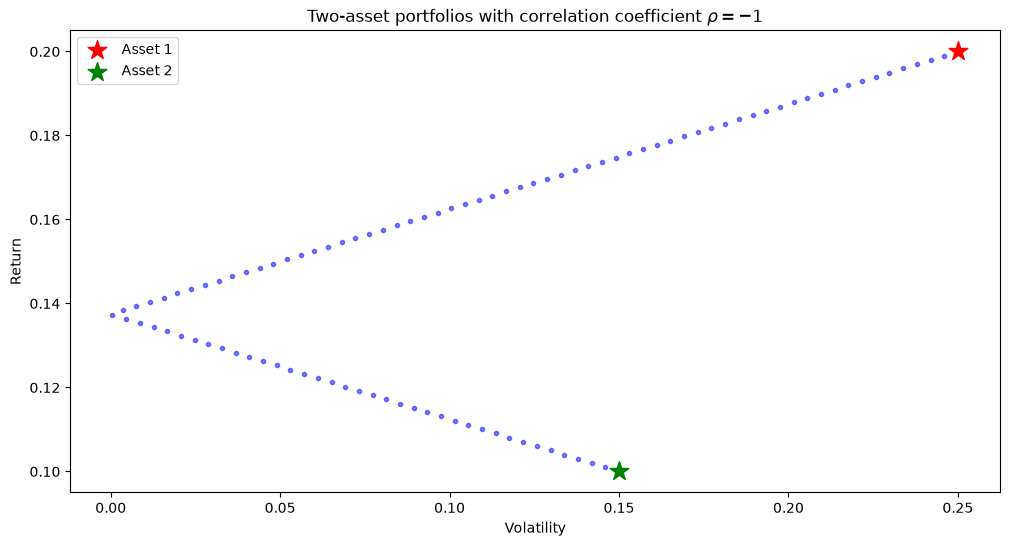

In [31]:
fig, ax = plt.subplots(figsize=(12, 6))

weights_1 = np.linspace(
    0, 1, 100
)  # Generate 100 points between 0 and 1 representing the weight of asset 1

for w_1 in weights_1:
    w_2 = 1 - w_1  # Calculate the weight of asset 2

    ret_p = calc_portfolio_return(
        w_1, w_2, ret1, ret2
    )  # Calculate portfolio return for each weight
    std_p = calc_portfolio_std(
        w_1, w_2, std1, std2, corr_coef_neg
    )  # Calculate portfolio volatility for each weight

    plt.scatter(
        x=std_p, y=ret_p, marker=".", color="blue", alpha=0.5
    )

plt.scatter(
    std1, ret1, color="red", marker="*", s=200, label="Asset 1"
)
plt.scatter(
    std2, ret2, color="green", marker="*", s=200, label="Asset 2"
)

plt.xlabel("Volatility")
plt.ylabel("Return")
plt.title(r"Two-asset portfolios with correlation coefficient $\rho=-1$")
plt.legend()
plt.show()


---

We will now build portfolios using the returns of two downloaded assets.

In [32]:
file_path = "https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python/refs/heads/Feb-2025/Tema_1_Activos_Intro/data/precios_corr_neg.csv"
prices_neg_df = pd.read_csv(file_path, index_col=0, parse_dates=True)
prices_neg_df.columns = ["Asset 1", "Asset 2"]
prices_neg_df.head()


,Asset 1,Asset 2
2010-01-04,117.000000,158.000000
2010-01-05,113.169161,159.774582
2010-01-06,111.074723,160.767536
2010-01-07,107.015024,162.645138
2010-01-08,104.983933,163.609577


In [33]:
# # Load asset prices from a local file
# prices_neg_df = pd.read_csv(
#     "../data/precios_corr_neg.csv", index_col=0, parse_dates=True
# )
# prices_neg_df.columns = ["Asset 1", "Asset 2"]
# prices_neg_df.head()


In [34]:
# Calculate logarithmic returns
returns_neg_df = np.log(prices_neg_df).diff().dropna()


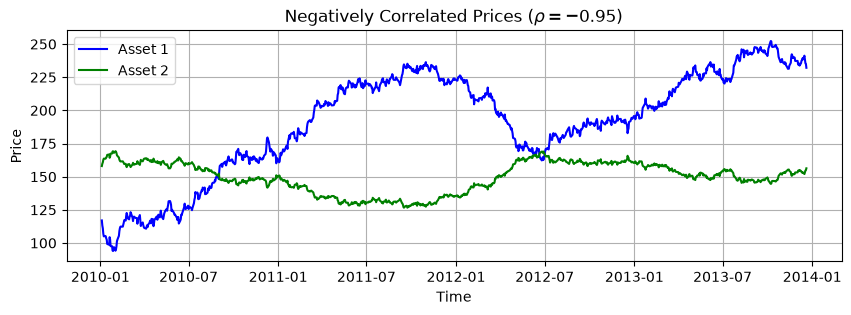

In [35]:
# Plot prices and show the return correlation coefficient in the title
plt.figure(figsize=(10, 3))

corr_neg = returns_neg_df.corr().iloc[0, 1]

plt.plot(prices_neg_df["Asset 1"], label="Asset 1", color="blue")
plt.plot(prices_neg_df["Asset 2"], label="Asset 2", color="green")

plt.title(f"Negatively Correlated Prices ($\\rho={corr_neg:.2f}$)")
plt.xlabel("Time")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.show()


In [36]:
# Define portfolio weights
w1 = 0.8
w2 = 0.2

# Calculate the mean and standard deviation of returns
mean_neg = returns_neg_df.mean()
std_neg = returns_neg_df.std()

print(mean_neg)
print(std_neg)

# Calculate portfolio return
r1 = mean_neg.iloc[0]
r2 = mean_neg.iloc[1]

print("Portfolio return:", calc_portfolio_return(w1, w2, r1, r2))

# Calculate portfolio volatility
vol1 = std_neg.iloc[0]
vol2 = std_neg.iloc[1]

print(
    "Portfolio volatility:",
    calc_portfolio_std(w1, w2, vol1, vol2, corr_coef_neg),
)


Asset 1    0.000686
Asset 2   -0.000011
dtype: float64
Asset 1    0.012476
Asset 2    0.006515
dtype: float64
Portfolio return: 0.0005464026795538537
Portfolio volatility: 0.008677642777012613


In [37]:
# Calculate daily portfolio returns
weights = np.array([w1, w2])  # (1, 2)

portfolio_returns = returns_neg_df @ weights.T  # (999, 2) @ (2, 1) = (999, 1)

print("Portfolio return:", portfolio_returns.mean())
print("Portfolio volatility:", portfolio_returns.std())


Portfolio return: 0.0005464026795538538
Portfolio volatility: 0.008747188300591333


In [38]:
# Random number generator
rng = np.random.default_rng(42)  # Set seed for reproducibility

# Generate random weights
num_portfolios = 1000

weights = rng.random(
    size=(num_portfolios, 2)
)  # Uniform distribution between 0 and 1 -> [0.0, 1.0)
weights = weights / np.sum(
    weights, axis=1, keepdims=True
)  # Normalize so that each row sums to 1

weights.shape


(1000, 2)

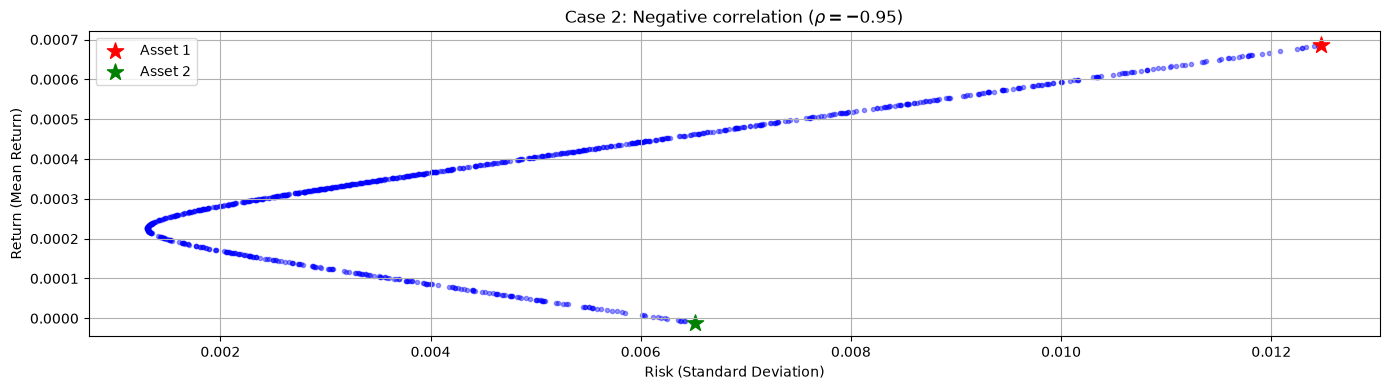

In [39]:
# Expected return and risk of asset 1
asset1_neg_mean, asset1_neg_std = asset_performance(returns_neg_df["Asset 1"])
# Expected return and risk of asset 2
asset2_neg_mean, asset2_neg_std = asset_performance(returns_neg_df["Asset 2"])
# Expected returns and risks of all calculated portfolios
ret_neg_mean, ret_neg_std = portfolio_performance(
    weights, returns_neg_df
)  # weights.shape = (1000, 2)

# Plot
plot_on_axis(
    ret_neg_mean,
    ret_neg_std,
    asset1_neg_mean,
    asset1_neg_std,
    asset2_neg_mean,
    asset2_neg_std,
    "blue",
    ".",
    "Case 2: Negative correlation",
    corr_neg,
)


---

### Case 3: $\quad$    $-1\leq \rho_{12} \leq 1$

* If $-1 \leq \rho_{12} \leq 1$, the assets have an **imperfect linear correlation**.

    - There are diversification benefits; the more negative the correlation, the greater the benefit.

    - Portfolio return is unchanged (remember that it does not depend on the relationship between the assets).
        - $E(\tilde R_P) = w_1 E(\tilde R_1) + w_2 E(\tilde R_2)$
        $$$$

    - Portfolio variance is:
        - $\sigma²(\tilde R_p)= \underset{Asset\ 1} {\underbrace{w_1²\sigma²(\tilde R_1)}}+\underset{Asset\ 2} {\underbrace{w_2²\sigma²(\tilde R_2)}}+ \underset{Relationship\ between\ assets} {\underbrace{2w_1w_2 \rho_{12} \sigma_1 \sigma_2}}$
        $$$$

    - Portfolio volatility is the square root of the variance.
        - $\sigma(\tilde R_p)= \sqrt{w_1²\sigma²(\tilde R_1)+w_2²\sigma²(\tilde R_2)+ 2w_1w_2 \rho_{12} \sigma_1 \sigma_2} $

In [40]:
weights_1 = np.linspace(0, 1, 100)
corr_coef_list = [-1, -0.8, -0.5, 0, 0.5, 1]

# Define a color map based on corr_coef_list
colors = ["#440154", "#3b528b", "#21918c", "#5ec962", "#3366CC", "#FF6633"]

# Set figure size
layout_width = 1200  # Width in pixels
layout_height = 700  # Height in pixels

# Create the Plotly figure
fig = go.Figure()

for idx, corr_coef_i in enumerate(corr_coef_list):
    ret_list = []
    std_list = []

    for w_1 in weights_1:
        w_2 = 1 - w_1
        ret_p = calc_portfolio_return(w_1, w_2, ret1, ret2)
        std_p = calc_portfolio_std(w_1, w_2, std1, std2, corr_coef_i)

        ret_list.append(ret_p)
        std_list.append(std_p)

    fig.add_trace(
        go.Scatter(
            x=std_list,
            y=ret_list,
            mode="markers",
            name=f"Corr {corr_coef_i}",
            marker=dict(color=colors[idx], size=8, opacity=0.5),
        )
    )

# Add individual asset points
fig.add_trace(
    go.Scatter(
        x=[std1],
        y=[ret1],
        mode="markers",
        marker=dict(color="red", size=20, symbol="star"),
        name="Asset 1",
    )
)
fig.add_trace(
    go.Scatter(
        x=[std2],
        y=[ret2],
        mode="markers",
        marker=dict(color="green", size=20, symbol="star"),
        name="Asset 2",
    )
)

# Configure title and axis labels
title_font_size = 20

fig.update_layout(
    title="Two-asset portfolio for different correlation coefficients",
    font=dict(size=title_font_size),
    title_x=0.5,
    xaxis_title="Volatility",
    yaxis_title="Return",
)

# Display the chart
fig.show()


ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

## 2. Calculating the minimum-volatility portfolio

We will calculate the minimum-variance portfolio:

* We start from the portfolio variance formula:

    - $\sigma^2_p= w_1^2\sigma^2_1+w_2^2\sigma^2_2+ 2w_1w_2 \rho_{12} \sigma_1 \sigma_2 $
    $$$$

* We substitute $w_2=1-w_1$, differentiate with respect to $w_1$, and set the derivative equal to 0:

    - $\dfrac{\partial \sigma^2_p}{\partial w_1}= 2w_1\sigma^2_1 - 2(1-w_1)\sigma^2_2 + 2(1-2w_1) \rho_{12} \sigma_1 \sigma_2 = 0$
    $$$$

* Solving for $w_1$:

    - $w_1 = \dfrac{\sigma_2²-\rho_{12} \sigma_1 \sigma_2}{\sigma_1²+\sigma_2²-2 \rho_{12} \sigma_1 \sigma_2}$

For two assets with correlation $\rho_{12} = -1$:

* $w_1 = \dfrac{\sigma_2²+\sigma_1 \sigma_2}{\sigma_1²+\sigma_2²+2 \sigma_1 \sigma_2} = \dfrac{\sigma_2(\sigma_1+\sigma_2)}{(\sigma_1+\sigma_2)²} = \dfrac{\sigma_2}{\sigma_1+\sigma_2}$

Applying this result to the two-asset portfolio example we have been using:

In [ ]:
p1 = std2 / (std1 + std2)
p2 = 1 - p1
print(f"Weight of asset 1: {100*p1:.2f}%")
print(f"Weight of asset 2: {100*p2:.2f}%")


Weight of asset 1: 37.50%
Weight of asset 2: 62.50%


In [ ]:
# Calculate portfolio return and volatility using the new weights
print(f"Portfolio return: {100*calc_portfolio_return(p1, p2, ret1, ret2):.2f} %")
print(
    f"Portfolio volatility: {100*calc_portfolio_std(p1, p2, std1, std2, corr_coef_neg):.2f} %"
)


Portfolio return: 13.75 %
Portfolio volatility: 0.00 %


**CONCLUSIONS**

Remember that with the initial weights and $\rho_{12}=1$ we obtained:

* $E(\tilde R_p) = 14$%

* $\sigma_p = 19$%

We have seen that with $\rho_{12}=-1$ and the minimum-variance portfolio formula we obtain:

* $E(\tilde R_p) = 13.75$%

* $\sigma_p = 0$%

Thanks to **diversification**, we obtain almost the same return with **no risk**.

## EXERCISE

Download data for Telefónica and Banco Santander for 2022 and 2023 and complete the following tasks:

1. Generate 100 portfolios by changing the weight of asset 1 in steps of 0.01. Plot all portfolios and the two individual assets in the return-risk plane.

2. Create the minimum-volatility portfolio and include it in the graph generated above.

3. Compare the return, volatility, skewness, and kurtosis of the two assets and the portfolio.